In [1]:
!pip -q install folktables scikit-learn matplotlib


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python3 -m pip install --upgrade pip


In [2]:
import numpy as np
import pandas as pd
from folktables import ACSDataSource, ACSPublicCoverage
from sklearn.ensemble import HistGradientBoostingClassifier

import ppi

In [3]:
source = ACSDataSource(survey_year="2018", horizon="1-Year", survey="person")
data = source.get_data(states=["CA", "TX", "NY", "FL", "GA", "MS"], download=True)
X, y_all, g_all = ACSPublicCoverage.df_to_numpy(data)
g_all = g_all.astype(int).astype(str)
X.shape

(425862, 19)

In [4]:
rng = np.random.default_rng(0)
perm = rng.permutation(len(y_all))
fit_idx, pool_idx = perm[:60000], perm[60000:]

model = HistGradientBoostingClassifier(max_iter=120, random_state=0).fit(X[fit_idx], y_all[fit_idx])
f = model.predict_proba(X[pool_idx])[:, 1]
y = y_all[pool_idx].astype(float)
g = g_all[pool_idx]
len(y)

365862

In [5]:
gaps = ppi.rectifier_gap(y, f, g)
pd.DataFrame([{"group": k, "pi": float((g == k).mean()), "delta": v} for k, v in gaps.items()]).round(5)

,group,pi,delta
0,1,0.64643,-0.00179
1,2,0.13504,0.00667
2,3,0.00532,-0.02184
3,5,0.00221,0.03876
4,6,0.08621,-0.00312
5,7,0.00176,-0.05227
6,8,0.08865,0.00880
7,9,0.03431,-0.00365


In [6]:
floor = ppi.budget_floor(g)
print("budget floor (Proposition 2):", round(floor))

budget floor (Proposition 2): 1704


In [7]:
res = ppi.evaluate(y, f, g, n_gold=1000, replicates=600)
pd.DataFrame([{
    "dataset": "ACS",
    "partition": "race",
    "K": len(res["groups"]),
    "worst_pooled": round(res["worst_pooled"], 3),
    "worst_per_group": round(res["worst_group"], 3),
    "width_ratio": round(res["width_ratio"], 1),
}])

,dataset,partition,K,worst_pooled,worst_per_group,width_ratio
0,ACS,race,8,0.013,0.18,8.0


In [8]:
sweep = []
for n_gold in (500, 1000, 2000, 5000, 10000):
    r = ppi.evaluate(y, f, g, n_gold=n_gold, replicates=200)
    sweep.append({"n_gold": n_gold, "above_floor": n_gold >= floor,
                  "worst_pooled": round(r["worst_pooled"], 3),
                  "worst_per_group": round(r["worst_group"], 3)})
sweep = pd.DataFrame(sweep)
sweep

,n_gold,above_floor,worst_pooled,worst_per_group
0,500,False,0.140,0.035
1,1000,False,0.015,0.180
2,2000,True,0.000,0.505
3,5000,True,0.000,0.860
4,10000,True,0.000,0.925


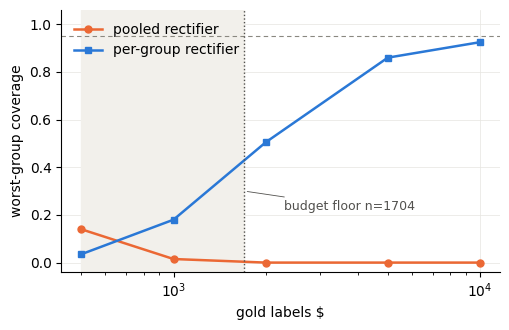

In [9]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(5.2, 3.4))
ax.axvspan(sweep.n_gold.min(), floor, color="#f2f0eb")
ax.axhline(0.95, color="#8a8880", lw=0.8, ls=(0, (4, 3)))
ax.plot(sweep.n_gold, sweep.worst_pooled, "-o", color="#eb6834", lw=1.8, ms=5, label="pooled rectifier")
ax.plot(sweep.n_gold, sweep.worst_per_group, "-s", color="#2a78d6", lw=1.8, ms=5, label="per-group rectifier")
ax.axvline(floor, color="#52514e", lw=1.0, ls=(0, (1, 1.6)))
ax.annotate(f"budget floor n={floor:.0f}", (floor, 0.30), xytext=(floor * 1.35, 0.22),
            fontsize=9, color="#52514e", arrowprops=dict(arrowstyle="-", color="#52514e", lw=0.6))
ax.set_xscale("log")
ax.set_xlabel("gold labels $")
ax.set_ylabel("worst-group coverage")
ax.set_ylim(-0.04, 1.06)
ax.legend(frameon=False, loc="upper left")
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.grid(color="#e6e5e0", lw=0.5)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig("repair.pdf")
plt.show()